# 2 · Computing OFAC's 50 percent rule

*Notebook 1.2: Step 2 of the session's four. In notebook 1.1, we added a hook in front of the agent with no rules yet, and the order was still drafted. In this notebook, we'll compute OFAC's 50 percent rule and give it to the guard.*

**Cell 2.0 · Connect.** Each notebook runs in its own kernel, so each one starts by connecting,
with the same setup as Cell 0.1 in notebook 1.1. The cell then shows where the order stands after the
earlier notebooks. If a notebook was skipped, Connect puts the reference answers in place, so this one
still works.

In [ ]:
# Cell 2.0 · Connect
import sys, os; sys.path.insert(0, os.path.join(os.path.expanduser("~"), "SageMaker", "workshop", "helpers"))
from session import connect
connect(globals())
show_scoreboard()

> **What this showed.** The cell shows *Setup complete*, followed by the order's scoreboard so far, with one line for each
> step the order has been through. After a kernel restart, run this cell again.

In this step, we'll take on the hardest of the four findings, sanctions. AnyCompany Components isn't
on any sanctions list, so no lookup will flag it. What blocks it is a set of relationships, namely who
owns whom, and how much, three levels up. We'll look at those facts in the graph, see why the two
obvious checks get the answer wrong, and then write OFAC's rule as a query and give it to the guard.

The facts are held in AnyCompany's supplier registry in Amazon Neptune, which has 50,000 suppliers and
the 5,000 companies that own and supply them.

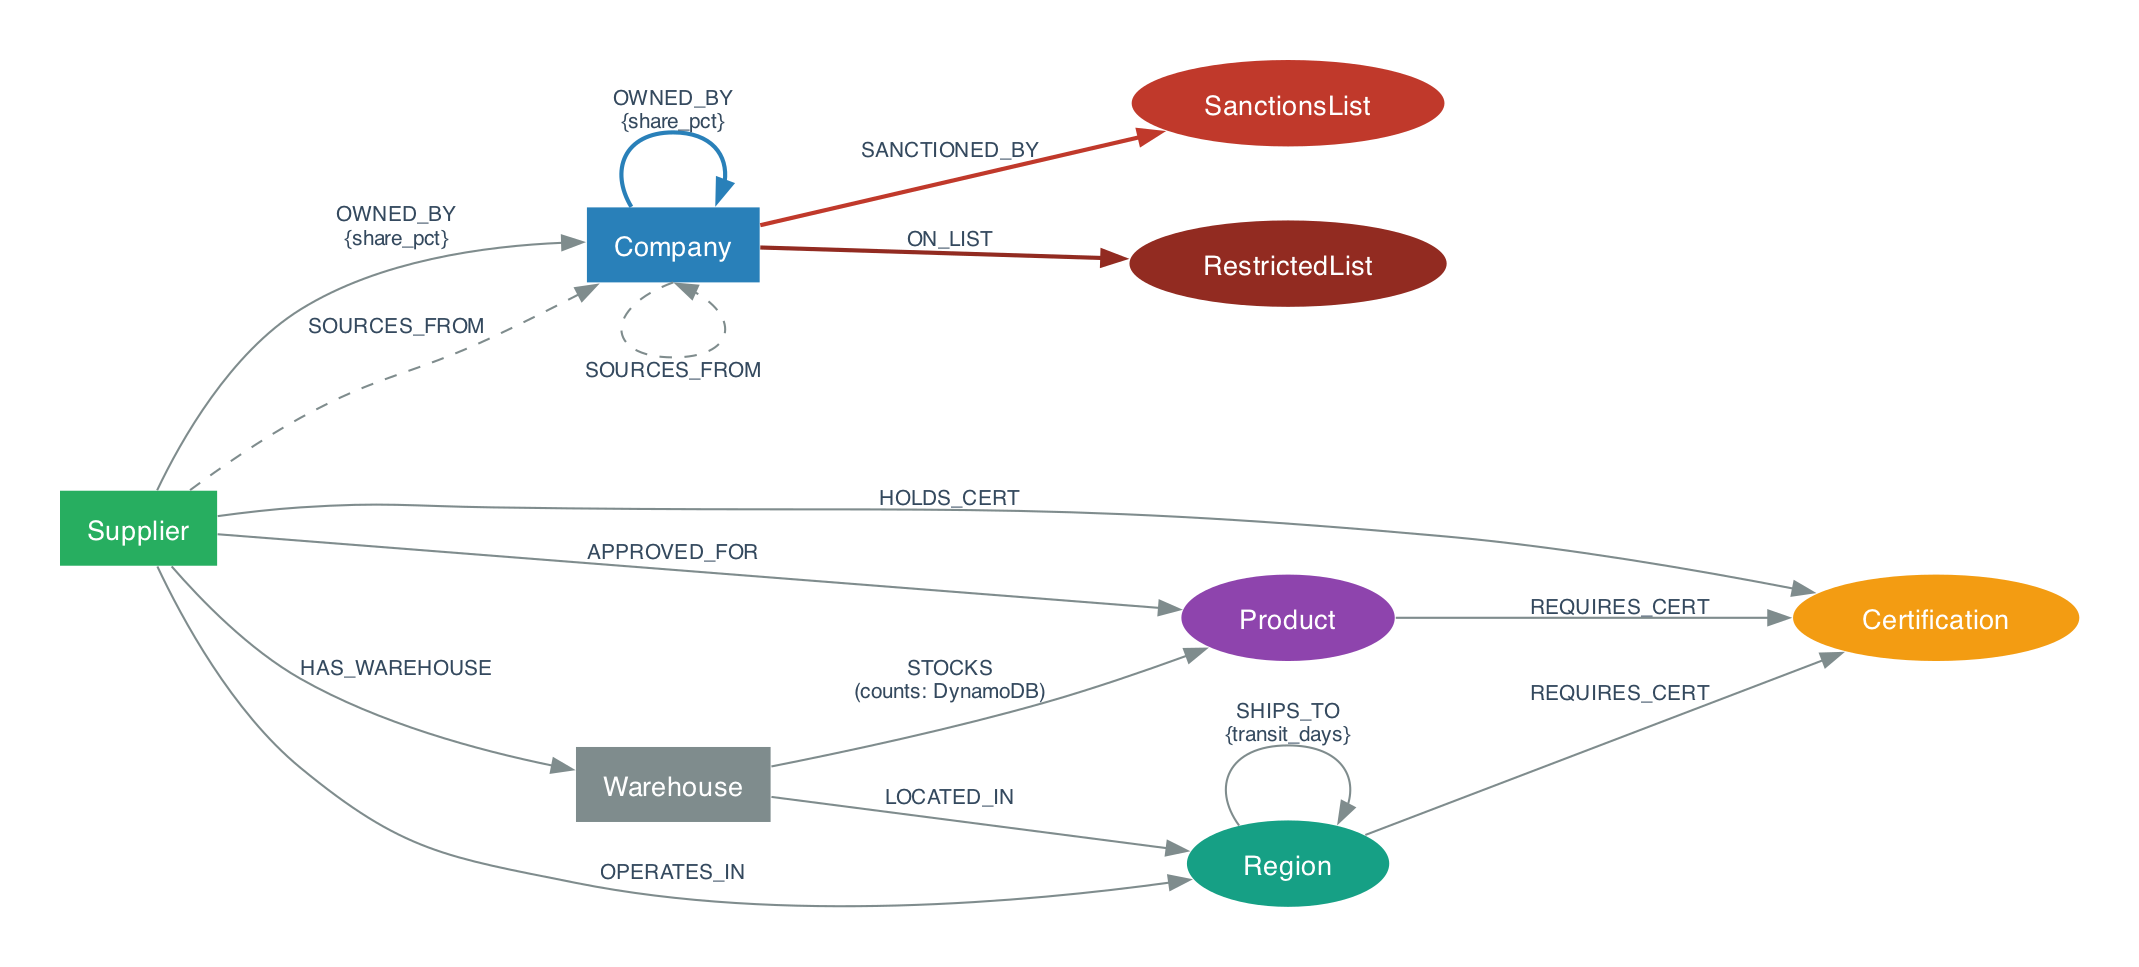

The parts of the model that matter here are the ones a rule has to follow. `OWNED_BY` runs from a
supplier or company to the company that owns it, and carries the stake on the edge (`share_pct`).
After the first hop, from the supplier, every hop runs from one `Company` to another, so an ownership
chain can be any length. `SOURCES_FROM` has the same two forms, for the supply chain. A sanctioned
company has a `SANCTIONED_BY` edge to the OFAC list, and a company on the UFLPA list has an `ON_LIST`
edge.

**Cell 2.1 · What it couldn't see.** We'll start where the agent started, with the supplier named on
the order, AnyCompany Components. From there, the query makes the two walks the agent would have
needed. Each one reads as a start, a walk and an end.

- **Start.** `MATCH (s:Supplier {name: $supplier_name})` finds the one vertex the order names, once.
  The name comes in as a parameter, from `params`.
- **Walk 1, up.** Inside `CALL { ... }`, `-[:OWNED_BY*1..]->` follows ownership edges from the
  supplier to its owner, then to that owner's owner, and so on. The `*1..` means one or more hops, as
  far as the chain goes, so the query says what to follow, not how deep the chain is. We leave it
  unbounded because we know this dataset, whose deepest chain is eight hops. In production, consider
  an upper bound chosen from your own data, as the note under Cell 0.3 explains.
- **End 1.** `(:Company)-[:SANCTIONED_BY]->(:SanctionsList)` is a company on the OFAC list.
- **Walk 2, down.** After `UNION`, the same shape follows `SOURCES_FROM` from the same `s` to its
  suppliers, and to theirs, and ends at a company that is `ON_LIST` the UFLPA Entity List.

Each match is a path `p` from the start to an end. `%%oc` runs the query in Neptune; choose the
**Graph** tab to see the paths. Vertices are coloured by label, so AnyCompany Components is the only
`Supplier`, the companies it reaches are `Company` vertices, and the two lists are where the walks
end. The edge labels show each stake.

*Predict: how many hops up is the OFAC list, and how many down is the UFLPA list?*

In [ ]:
%%oc -qp params -d name -de share_pct -l 40 -rel 40
// Cell 2.1 · What it couldn't see
// Find the supplier on the order once; both walks start from it
MATCH (s:Supplier {name: $supplier_name})
CALL {
  // Walk 1: up its owners, any number of hops, to the sanctions list
  WITH s
  MATCH p = (s)-[:OWNED_BY*1..]->(:Company)-[:SANCTIONED_BY]->(:SanctionsList)
  RETURN p
  UNION
  // Walk 2: down its supply chain, any number of hops, to the UFLPA list
  WITH s
  MATCH p = (s)-[:SOURCES_FROM*1..]->(:Company)-[:ON_LIST]->(:RestrictedList)
  RETURN p
}
RETURN p

> **What you should see.** Two ownership routes lead up to OFAC's list and meet at AnyCompany Components Holdings BV, with 30%
> held through AnyCompany Group SA and 25% through AnyCompany Capital LP. Three `SOURCES_FROM` hops lead
> down to AnyCompany Polysilicon Co., which is on the UFLPA list.
>
> **Why it matters.** Neither depth appeared anywhere in the query. Another supplier would have a different chain, of a
> different length, and the same query, with a different `$supplier_name`, would still find it. A table lookup can't do this, which is
> why these facts are kept in a graph.

**Is AnyCompany Components sanctioned?** The walk shows a listed company upstream, but that alone
doesn't settle it. Under OFAC's **50 Percent Rule**, an entity is blocked when **blocked** owners
together hold 50% or more of it, directly or indirectly. The rule says *blocked* rather than *listed*,
because an owner can itself be blocked by *its* owners.

OFAC explains the rule in numbered answers to frequently asked questions, its
[FAQs on the 50 Percent Rule](https://ofac.treasury.gov/faqs/topic/1521). Three of them matter here.
FAQ 398 says the rule is about ownership, not control. FAQ 399 says that stakes held by different
blocked owners add up. FAQ 401 works through five ownership examples. The picture shows three of
them, and Cell 2.4 checks your query against all five, plus FAQ 399.

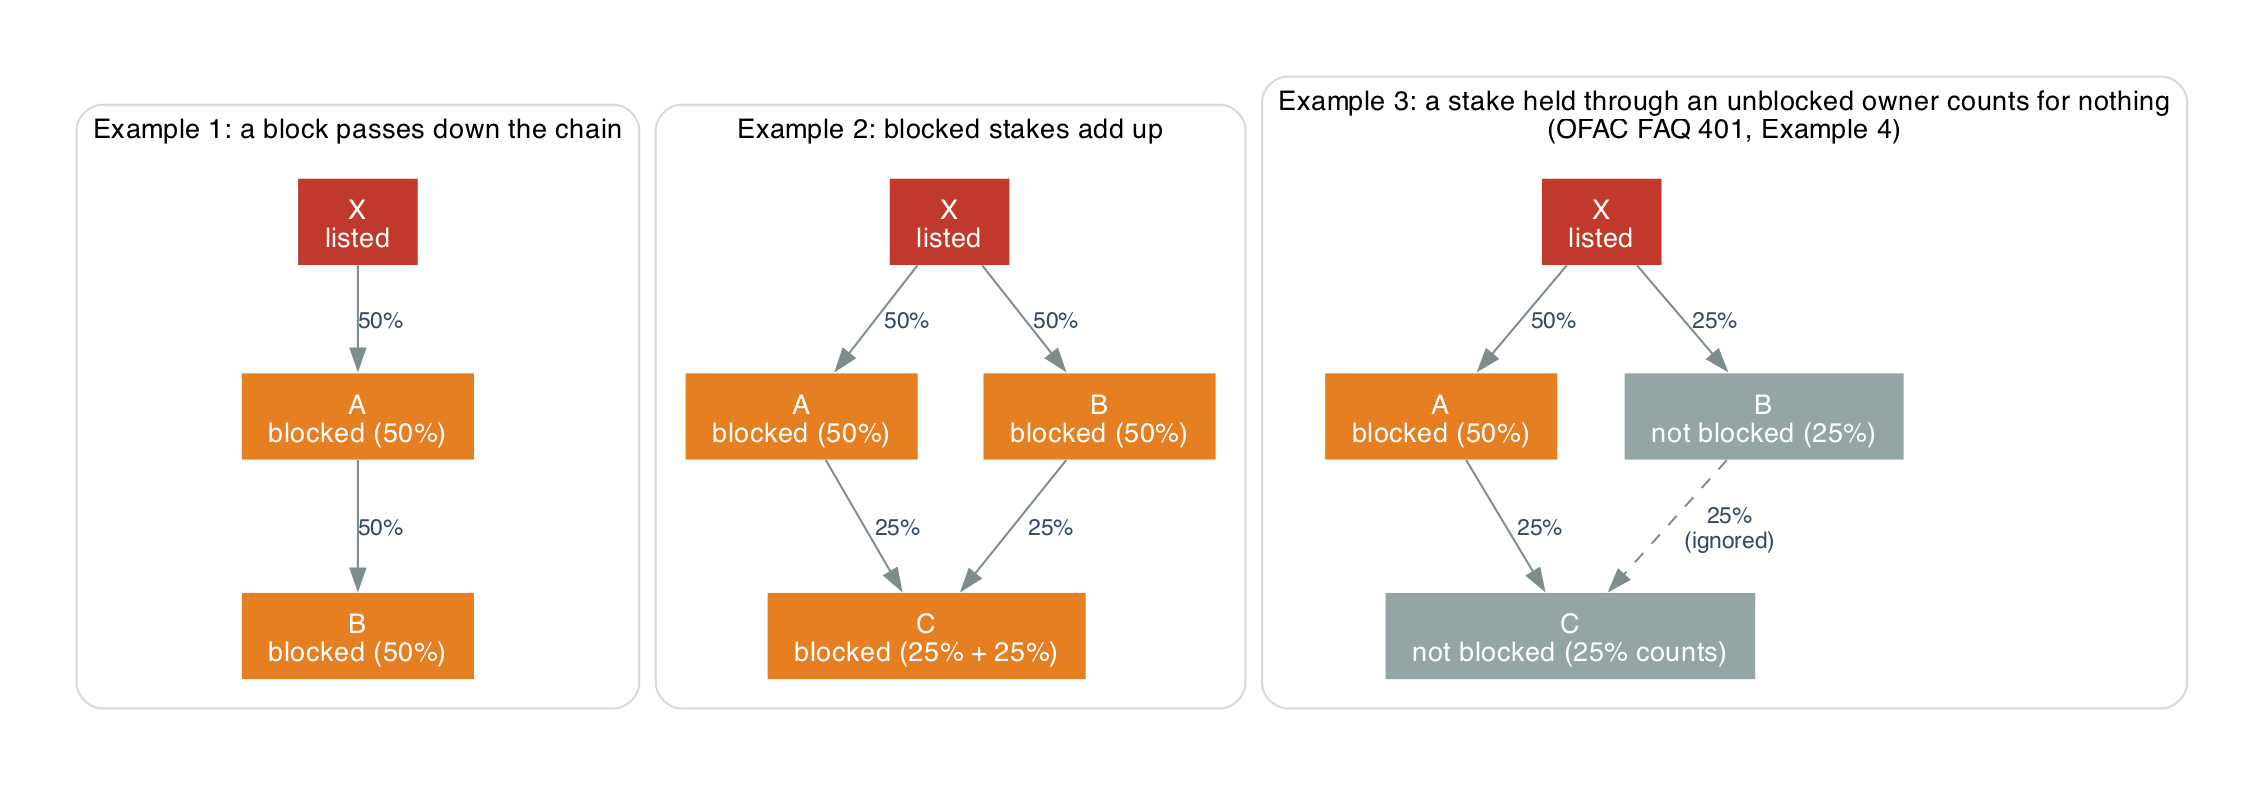

- **Example 1.** X, which is listed, owns 50% of A, so A is blocked. A owns 50% of B, so B is blocked
  as well. The block passes down one ownership level at a time.
- **Example 2.** Neither A nor B owns 50% of C on its own, but both are blocked, so their stakes add
  up to 25% plus 25%. AnyCompany Components Holdings BV has exactly this shape, at 30% plus 25%.
- **Example 3** (OFAC's FAQ 401, Example 4). B isn't blocked, so its stake in C counts for nothing,
  even though X stands behind it.

**Cell 2.2 · Two simple checks.** Before we write the rule, it's worth trying the two checks most
teams start with, across all 50,000 suppliers.

- **Option A · Screen the name** asks whether a direct owner of the supplier is on the list. This is
  what most vendor screening does. It's a one-hop join, so it runs inside the helper.
- **Option B · Any listed owner upstream** blocks the supplier if a listed company sits anywhere up
  its ownership chain, at any depth, whatever its stake. Its pattern is in the cell, and it's the same
  walk as in Cell 2.1.

The table shows how many suppliers each option blocks. Under it, the cell draws the two named
suppliers' ownership up to the listed firm, before any rule has run, with each option's verdict under
each supplier.

**What runs, and where.**

- `two_simple_checks(...)`, in [`helpers/session.py`](../helpers/session.py), runs one count per option over every
  supplier: `MATCH (s:Supplier) WHERE <pattern> RETURN count(s)`. Option A's pattern is
  `SCREEN_NAME` in the same file, `(s)-[:OWNED_BY]->(:Company)-[:SANCTIONED_BY]->(:SanctionsList)`,
  one hop. Option B's is the `ANY_LISTED_OWNER` pattern in the cell.
- It then runs the same patterns for the two named suppliers, to get each option's verdict on them,
  and `show_ownership` in [`helpers/ui.py`](../helpers/ui.py) draws their ownership.

*Predict: OFAC blocks AnyCompany Components but not AnyCompany Electronics, where a sanctioned firm
holds only 20%. Which option gets both right?*

In [ ]:
# Cell 2.2 · Two simple checks
# Option B: block if a listed company sits anywhere upstream, at any depth, whatever its stake.
ANY_LISTED_OWNER = "(s)-[:OWNED_BY*1..]->(:Company)-[:SANCTIONED_BY]->(:SanctionsList)"
two_simple_checks(ANY_LISTED_OWNER)

> **What you should see.** Neither option gets both right. Option A passes AnyCompany Components, because its direct owner isn't
> listed. Option B blocks AnyCompany Electronics, along with hundreds of other suppliers that only have
> a minority sanctioned stake somewhere upstream. The drawing shows why both miss. The same listed firm
> sits above both suppliers, and what separates them is the stakes on the edges, 30% plus 25% on one
> side and 20% on the other, which neither option reads.
>
> **Why it matters.** One check is too narrow and the other too broad, and neither takes the stakes into account. Whether
> an entity is blocked depends on whether its owners are blocked, so the answer has to be
> **computed**, one level at a time. That's the query we write next.

**Cell 2.3 · ✏️ The 50% rule.** Because the rule is defined in terms of itself, we compute it in
rounds. Every listed company starts out blocked, and the next cell takes care of that. After that, a
single query, run again and again, blocks every entity whose **already blocked** owners hold 50% or
more of it. Each round pushes the block one ownership level further down. When a round blocks
nothing new, we've reached the answer, which is called a fixpoint.

Write **one round** of the rule. The query needs four parts, in this order.

1. **Match** every ownership edge from an entity to an owner that is already blocked. Ownership is
   the `OWNED_BY` edge, from the owned entity to its owner, and a blocked vertex has `blocked` set to
   `true`.
2. **Add up**, for each entity, the stakes held by those blocked owners. The stake is the edge's
   `share_pct` property, and openCypher aggregates with `WITH` and `sum()`.
3. **Keep** only the entities where that total is at least `$ofac_threshold`, and that aren't blocked
   yet. The threshold is a parameter rather than a number in the query. It comes from
   `queries/rule_settings.json`, where it's set to 50, and every run of the query passes it in. Most
   vertices don't have a `blocked` property at all, so treat a missing value as `false`.
4. **Mark** each of those entities as blocked, record the total on it as `blocked_share`, and return
   how many were newly blocked, as a column named `newly_blocked`.

It's important to filter on the owner being blocked **before** adding up the stakes, because that's
what makes the stake in Example 3 count for nothing. If you need a reminder of the syntax, the
cheat sheet (`4 - openCypher cheat sheet.ipynb`, section 4) has a query with the same shape. Run the
cell to save `queries/ownership_50pct.cypher`.

In [ ]:
%%writefile queries/ownership_50pct.cypher
// Cell 2.3 · ✏️ The 50% rule
// One round of OFAC's 50 Percent Rule: an entity becomes blocked when owners that are
// ALREADY blocked together hold 50% or more of it. Returns how many it newly blocked.
//
// ✏️ 1. Match each OWNED_BY edge to an owner that is already blocked.
// ✏️ 2. Add up those owners' stakes for each entity.
// ✏️ 3. Keep the entities at $ofac_threshold or more (50, from rule_settings.json) that aren't blocked yet.
// ✏️ 4. Mark them blocked, record the total, and return how many as newly_blocked.
RETURN 0 AS newly_blocked

<details>
<summary>🔑 Reveal the Cell 2.3 solution</summary>

Replace the cell body below the <code>%%writefile</code> line with this, and run the cell again.

```cypher
// One round of OFAC's 50 Percent Rule (OFAC FAQs 399 and 401).
// An entity becomes blocked when owners that are ALREADY blocked together hold
// $ofac_threshold% or more of it (50, from queries/rule_settings.json). Ownership
// through an entity that is not blocked counts for nothing (FAQ 401 Examples 4 and 5), which is why this only looks one hop up at
// owners whose blocked flag is already set.
//
// verify.apply_ownership_rule() seeds the listed companies as blocked, then runs
// this query again and again until it returns 0: each round pushes the rule one
// ownership level further down. The graph has no ownership cycles and a round only
// ever ADDS blocks, so it always terminates.
MATCH (e)-[o:OWNED_BY]->(owner)
WHERE owner.blocked = true
WITH e, sum(o.share_pct) AS blocked_share
WHERE blocked_share >= $ofac_threshold AND coalesce(e.blocked, false) = false
SET e.blocked = true, e.blocked_share = blocked_share
RETURN count(e) AS newly_blocked
```

</details>

**Cell 2.4 · Run the 50% rule, and check it.** This cell runs the query the way it would run in
production, and the loop is shown in full.

- `seed_ownership_rule()` clears the results of the last run and marks every company on the list as
  `blocked = true`. It also marks them `listed = true`, so the report can tell later whether the list
  has changed.
- The loop runs the query once per round, for up to 25 rounds, and stops when a round blocks
  nothing. If it never stops, the query is blocking the same entities again, and the `coalesce` line
  is the place to look.
- `check_ownership_rule(rounds)` records the run, and then checks the query against OFAC's six worked
  examples, FAQ 399 and the five examples in FAQ 401, each built as a small separate graph, and
  against the named entities in AnyCompany's graph. Each card is titled with OFAC's own number, and a
  line under the title says, in plain words, what the example shows. It draws each of those graphs as your query left it, with an arrow from each owner to the
  company it owns, labelled with the stake, and every entity your query blocked in red.

**What runs, and where.**

- `seed_ownership_rule()` and `ownership_round()` are in [`helpers/verify.py`](../helpers/verify.py). A round runs
  your [`your-guard/queries/ownership_50pct.cypher`](../your-guard/queries/ownership_50pct.cypher) once, with `$ofac_threshold` from
  [`your-guard/queries/rule_settings.json`](../your-guard/queries/rule_settings.json), and returns its `newly_blocked`.
- `check_ownership_rule(rounds)`, in [`helpers/session.py`](../helpers/session.py), does three things.
  - It records the run as a `PolicyRun` vertex (`record_ownership_rule()` in `verify.py`), which
    the report checks before it trusts any `blocked` flag.
  - It checks your query against OFAC's examples with `check_ofac_examples()` in `verify.py`. Each
    example from `OFAC_EXAMPLES` is built in Neptune as a few `OfacExample` vertices with
    `OWNED_BY` edges, your query runs on them until nothing changes, and the result is read back and
    the vertices are deleted.
  - It reads `blocked` and `blocked_share` on AnyCompany's named entities, and draws both checks.
- On a FAIL, your query is kept as `.mine`, and the reference is loaded and run instead.

*Predict: the longest ownership chain below a listed company is four levels. How many rounds will it
take until nothing new is blocked?*

In [ ]:
# Cell 2.4 · Run the 50% rule, and check it
seed_ownership_rule()                 # every company on the list starts out blocked

rounds = []
for _ in range(25):
    newly_blocked = ownership_round()   # your query, once: how many it newly blocked
    rounds.append(newly_blocked)
    if not newly_blocked:               # nothing new: the fixpoint
        break

check_ownership_rule(rounds)            # OFAC's six worked examples, and AnyCompany's graph

> **What you should see.** The bars show four rounds that block something, one for each ownership level below the list, and a
> fifth that blocks nothing. All six OFAC diagrams say PASS. In Example 4, C stays grey because its only
> blocked owner, A, holds 25% of it. In Example 5, neither A nor B is blocked, so C stays grey even
> though the two of them own all of it. In AnyCompany's graph, Holdings BV is blocked at 55% (30% from Group SA plus 25% from Capital LP), and
> the 20% branch to AnyCompany Electronics stays grey. The last bars compare the rule with options A
> and B. If the check fails, its diagram says FAIL and shows which entity came out wrong, your query is
> kept as `.mine`, and the reference is loaded and recomputed.
>
> **Why it matters.** A query that sums every stake, without first filtering on blocked owners, would pass on AnyCompany's
> data but fail OFAC's Examples 4 and 5, which is why the check uses the regulator's own examples. The
> result is now stored as properties on the vertices (`blocked` and `blocked_share`), so when the agent
> acts, the guard only has to read it.

<div class="alert alert-block alert-warning"><b>Stuck?</b> If the check fails, your query is kept as <code>queries/ownership_50pct.cypher.mine</code>, and the reference is
loaded and recomputed, so you can carry on either way. If a later report says <code>ownership-rule</code>, the
50% rule hasn't been run against the current list. In either case, or to skip writing the rule, run
<code>catch_up("ownership")</code> in a new cell.</div>

**Cell 2.5 · The rule's result, in the graph explorer.** Cell 2.4 drew AnyCompany's graph from the
check. This cell reads it straight from Neptune, so you can explore it. It runs the same walk as Cell
2.1, for both named suppliers, now that the rule has written `blocked` and `blocked_share` onto the
vertices.

- `-g blocked` colours the vertices by their `blocked` property: **orange** for an entity the rule
  blocked, and **blue** for everything else, including the OFAC list itself.
- `-de share_pct` puts each stake on its `OWNED_BY` edge.
- In the **Graph** tab, click a vertex to see its `blocked_share`, the stake held by its blocked
  owners.

*Predict: AnyCompany Industries OAO, which is listed, sits upstream of both suppliers. Which of the
companies in between will be orange?*

In [ ]:
%%oc -qp params -g blocked -d name -de share_pct -l 40 -rel 40
// Cell 2.5 · The rule's result, in the graph explorer
MATCH (s:Supplier) WHERE s.name IN $named_suppliers
MATCH p = (s)-[:OWNED_BY*1..]->(:Company)-[:SANCTIONED_BY]->(:SanctionsList)
RETURN p

> **What you should see.** The whole chain above AnyCompany Components is orange, which means blocked. AnyCompany Group SA is 60% held
> by the listed firm, AnyCompany Trust Ltd 51%, and AnyCompany Capital LP is wholly held by Trust.
> Holdings BV is blocked because its two blocked owners hold 30% plus 25%, or 55%. On the other side,
> AnyCompany Electronics Group and AnyCompany Electronics stay blue, because the listed firm's 20% is
> below the threshold.
>
> **Why it matters.** The same listed company leads to two opposite answers, and the graph shows where they split: at the
> first entity whose blocked owners hold less than 50%. This is the reasoning behind every sanctions
> block the guard makes, and it's why option B, "any listed owner upstream", gave the wrong answer.

**Cell 2.6 · Teach it the rule, and send the order.** Now we give the guard two rules. The first
covers the basics, meaning the supplier is active, approved for the product and licensed for the
region. The second covers sanctions, and reads the result of the 50% rule to see whether the supplier
is `blocked`, and through which owners. The cell then runs the same lines as Cell 1.3, with your hook,
the same agent and the same request.

**What runs, and where.**

- The same functions as in Cell 1.3. The only new line is `install_rules(["basics", "sanctions"])`,
  which switches on those two rules in [`your-guard/queries/violations.cypher`](../your-guard/queries/violations.cypher).

*Predict: what will the model read this time, and what will it tell the person who asked?*

In [ ]:
# Cell 2.6 · Teach it the rule, and send the order
install_rules(["basics", "sanctions"])

agent = build_agent(guard=NeptuneGuardPlugin(rules=reload(guard_rules)))
reply = ask(agent, HEADLINE)

record("Step 2", reply)

> **What you should see.** The trace shows `[BLOCKED] draft_purchase_order(...)`, with the block message under it, saying that
> *blocked owners hold 100% of AnyCompany Components*. It then shows `[ok]
> recommend_alternatives(...)`, and a reply that explains the block and offers suppliers that pass. The
> scoreboard now reads `Step 2   BLOCKED: 1 of 4 problems caught`.
>
> **Why it matters.** Nothing in the agent changed between Step 1 and Step 2. The guard has one more rule, and that rule
> caught a problem no prompt could have found, three ownership levels above the supplier. Because the
> hook returned the reason as the tool's result, the model could explain the block rather than fail
> silently.

<div class="alert alert-block alert-success"><b>In your system.</b> Keep the relationships your rules follow in a graph, especially those of unknown depth, such as
ownership, supply, delegation or dependencies. When a fact is derived, like "blocked under the 50%
rule", compute it whenever its inputs change, and have the guard read the result.</div>

<div class="alert alert-block alert-info"><b>In production.</b> No regulator offers an API that answers "is this supplier blocked?", because a company blocked
under the 50% rule isn't on any list. OFAC publishes the SDN list as files on its
<a href="https://sanctionslist.ofac.treas.gov/" target="_blank">Sanctions List Service</a>, and the
<a href="https://www.trade.gov/consolidated-screening-list" target="_blank">Consolidated Screening List</a> combines it with
other U.S. export and sanctions lists, but neither says who owns whom. Ownership stakes are licensed
from commercial providers. A production guard downloads the lists on a schedule, matches their
entries to the licensed ownership data, and reruns the 50% rule from this step whenever either one
changes. The guard reads the stored result at action time, as yours does, so no action waits on an
outside service. Cells G.7 and G.8 in Go deeper land the real SDN list in Amazon S3.</div>

**Next: open `1.3 - Checking every rule in one report.ipynb`**, in this folder, for Step 3 · Checking every rule in one report.

Your work is saved in `your-guard/`, so the next notebook picks it up when it connects.